In [ ]:
import numpy as np
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from mads.lib.path import assets

# 1. Introduction - SIADS 521 Assignment 3 - Edward Lippens

Where are the strongest data science-related labor markets in the United States, and how do employment concentration, wages, and geographic patterns vary across occupational families?

This project explores the U.S. data science labor market using five years of Bureau of Labor Statistics data (2021–2025). The interactive dashboard compares employment, wages, and occupational concentration across states and five related job families, allowing users to explore geographic differences and changes over time.

**Live Interactive Dashboard:**  
https://data-science-labor-market.streamlit.app/

**Video Description:**

https://youtu.be/dTNId6PjgEY

**GitHub Link:**

https://github.com/jlippens-umich/data-science-labor-market/tree/main

**Dashboard Screenshot:**

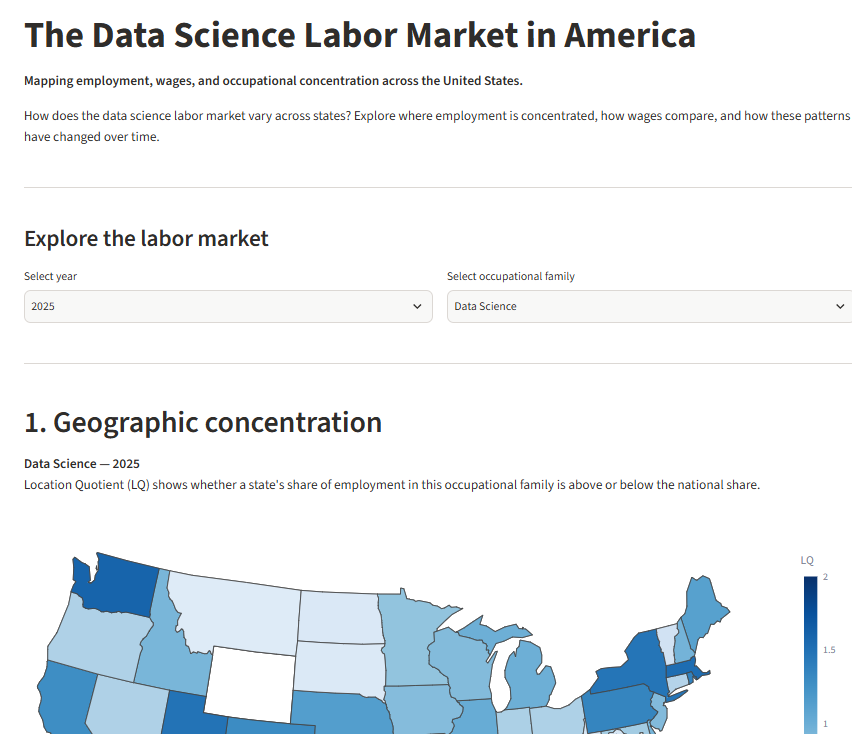

# 2. Library Choice and Fit

### Plotly

I selected **Plotly for Python (Plotly.py)** because it supports interactive visualizations, geographic maps, and statistical charts. It was a good fit for exploring the employment, wage, geographic, and time-based dimensions of the OEWS dataset.

- **Creator:** Plotly, Inc.
- **License:** MIT License (open source).
- **Installation:** `pip install plotly`
- **Approach:** Primarily declarative, using Plotly Express, with procedural customization available through Graph Objects.

### Jupyter Integration and Limitations

Plotly integrates directly with Jupyter Notebook, displaying interactive charts inline with hover, zoom, and pan capabilities. Plotly Express simplifies chart creation, while Graph Objects provides greater customization. Some specialized visualizations require additional coding, and large datasets can affect rendering performance.

### Why Plotly and Alternative Considered

Plotly supported all five visualization types in this project, including geographic maps and my custom beeswarm. Its interactive hover information and customization capabilities also made it suitable for developing visualizations in Jupyter and incorporating them into a public-facing Streamlit dashboard.

I also considered **Seaborn**, an open-source statistical visualization library created by Michael Waskom and licensed under BSD-3-Clause. Although Seaborn offers built-in statistical charts, including swarm plots, it relies on Matplotlib and primarily produces static visualizations. I chose Plotly because its interactive capabilities better supported the dashboard's exploration and linked controls.

# 3. Data

The data comes from the U.S. Bureau of Labor Statistics (BLS), Occupational Employment and Wage Statistics (OEWS) program. I used the annual May All Data files for 2021–2025.

- **Source:** [BLS Occupational Employment and Wage Statistics](https://www.bls.gov/oes/tables.htm)
- **License:** Public domain; attribution to the BLS is requested.
- **Dataset size:** 2,497 records after initial filtering across five years.
- **Format:** Tab-delimited text files (.txt).

**Key columns used:**

| Column | Description |
|---|---|
| YEAR | Estimate year |
| AREA / AREA_TITLE | Geographic identifier and name |
| OCC_CODE / OCC_TITLE | Occupation SOC code and title |
| TOT_EMP | Estimated employment |
| A_MEAN / A_MEDIAN | Mean and median annual wages |
| JOBS_1000 | Employment per 1,000 jobs |
| LOC_QUOTIENT | Relative employment concentration |
| EMP_PRSE / MEAN_PRSE | Relative standard errors for employment and mean wages |

## Data Cleaning and Filtering 

In [ ]:
#File locations
DATA_FILES = {
    2021: "all_data_M_2021.txt",
    2022: "all_data_M_2022.txt",
    2023: "all_data_M_2023.txt",
    2024: "all_data_M_2024.txt",
    2025: "all_data_M_2025.txt"
}

def load_oews_year(year, file_path = None):
    """
    Import one annual BLS OEWS dataset.

    TXT files are tab-delimited.

    All columns are initially read as strings to preserve occupational codes, geographic codes, and BLS special markers.
    """

    if file_path is None:
        file_path = assets.find(DATA_FILES[year])

    df=pd.read_csv(
        file_path,
        sep='\t',
        dtype=str,
        encoding='utf-8-sig',
        low_memory = False
    )

    # Standardize column names

    df.columns = df.columns.str.strip().str.upper()

    # Add source year
    df["YEAR"]= year

    return df
    
    


In [ ]:
# load 2025 Data as test

df_2025 = load_oews_year(2025)

#print(df_2025.shape)
print(df_2025.head(1))
#print(df_2025.dtypes)

In [ ]:
# Cleaning Data for 2021 - 2025

SOC_CODES = [
    "13-1111",  # Management Analysts
    "13-1161",  # Market Research Analysts
    "15-1211",  # Computer Systems Analysts
    "15-1221",  # Computer and Information Research Scientists
    "15-1242",  # Database Administrators
    "15-1243",  # Database Architects
    "15-1252",  # Software Developers
    "15-2031",  # Operations Research Analysts
    "15-2041",  # Statisticians
    "15-2051"   # Data Scientists
]

NUMERIC_COLUMNS = [
    "TOT_EMP", "EMP_PRSE", "JOBS_1000", "LOC_QUOTIENT",
    "PCT_TOTAL", "PCT_RPT", "H_MEAN", "A_MEAN", "MEAN_PRSE",
    "H_PCT10", "H_PCT25", "H_MEDIAN", "H_PCT75", "H_PCT90",
    "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"
]

def clean_oews_data(df, year=None):
    """
    Filter and clean OEWS data for selected occupations, 
    U.S. and state estimates, cross-industry, all ownership.

    Converts numeric fields and retains BLS special-value
    information in corresponding STATUS columns. 
    """
    df=df.copy()

    # Standardize categorical fields
    for col in ["AREA_TYPE", "NAICS", "OWN_CODE",
                "O_GROUP", "OCC_CODE"]:
        df[col].astype("string").str.strip()

    # Apply filters
    df = df[
        (df["NAICS"] == "000000") &
        (df["OWN_CODE"] == "1235") &
        (df["AREA_TYPE"].isin(["1", "2"])) &
        (df["O_GROUP"].str.lower() == "detailed") &
        (df["OCC_CODE"].isin(SOC_CODES))
    ].copy()

    # Convert numeric fields and retain marker statuses
    for col in NUMERIC_COLUMNS:
        if col not in df.columns:
            continue

        raw = df[col].astype("string").str.strip()

        status = pd.Series(
            "published", index=df.index, dtype= 'string'
        )

        status[raw.isna() | raw.eq("")] = "missing"
        status[raw.eq("#")]= "at_or_above_reporting_ceiling"
        status[raw.isin(["*", "**"])] = "below_reporting_threshold"

        cleaned = raw.str.replace(",", "", regex = False)
        cleaned = cleaned.where(status.eq("published"))

        df[col] = pd.to_numeric(cleaned, errors = "coerce")
        df[f"{col}_STATUS"] = status

    #Geography label
    df["GEO_LEVEL"] = df["AREA_TYPE"].map({
        "1": "United States",
        "2": "State"
    })
    
    # Consistent year format
    if year is not None:
        df["year"] = int(year)

    return df.reset_index(drop=True)

In [ ]:
#Concatenate datasets

def build_oews_dataset(years = None):
    """
    Import, clean, and concatenate multiple annual OEWS files.
    Processes one year at a time.
    """

    if years is None:
        years = sorted(DATA_FILES.keys())

    yearly_data = []

    for year in years:
        print(f"Processing {year}...")

        raw = load_oews_year(year)
        cleaned = clean_oews_data(raw, year=year)

        yearly_data.append(cleaned)

        print(f"  Retained {len(cleaned):,} records")

        del raw
    combined = pd.concat(yearly_data, ignore_index = True)

    combined = combined.sort_values(
        ["YEAR", "AREA_TYPE", "AREA_TITLE", 'OCC_CODE']
    ).reset_index(drop=True)

    return combined

# Build the combined dataset

oews_all = build_oews_dataset()
        

In [ ]:
#oews_all.info()

In [ ]:
# Verification of consolidated data

#print("YEARvsyear")
#print(oews_all[["YEAR", "year"]].value_counts().sort_index())

#print("ANNUAL:")
#print(oews_all["ANNUAL"].value_counts(dropna=False))

#print("\nHOURLY:")
#print(oews_all["HOURLY"].value_counts(dropna=False))

In [ ]:
oews_all = oews_all.drop(columns = ['year', 'PCT_TOTAL', 'PCT_RPT', 'ANNUAL', 'HOURLY'])

In [ ]:
# Verify records and codes
# Records per year
#print("RECORDS BY YEAR")
#display(oews_all.groupby("YEAR").size())

# National and state records by occupation and year
#print("GEOGRAPHIC COVERAGE")

#coverage = (
#    oews_all
#   .groupby(["YEAR", "OCC_CODE", "AREA_TYPE"])
#    .size()
#    .unstack("AREA_TYPE", fill_value=0)
#)

#display(coverage)

In [ ]:
# Remove duplicate lowercase year column
oews_all = oews_all.drop(columns=["year"], errors="ignore")

# Remove columns that are completely empty
empty_columns = oews_all.columns[
    oews_all.isna().all()
].tolist()

#print("Removing empty columns:", empty_columns)

oews_all = oews_all.drop(columns=empty_columns)

# Verify
#oews_all.info()


In [ ]:
#Checking for duplicate records
duplicate_count = oews_all.duplicated(
    subset=["YEAR", "AREA", "OCC_CODE"]
).sum()

print("Duplicate records:", duplicate_count)

In [ ]:
# Creating Job-Family mappings

JOB_FAMILY_MAP = {
    "Data Science": [
        "15-2051"
    ],
    "AI/ML Engineering": [
        "15-1252",
        "15-1221"
    ],
    "Statistics": [
        "15-2041",
        "15-2031"
    ],
    "Business Analytics": [
        "13-1111",
        "13-1161"
    ],
    "Computer Science/Data Engineering": [
        "15-1252",
        "15-1242",
        "15-1243",
        "15-1211"
    ]
}

# Reverse mapping: SOC code -> job family or families

SOC_TO_FAMILIES = {}

for family, codes in JOB_FAMILY_MAP.items():
    for code in codes:
        SOC_TO_FAMILIES.setdefault(code, []).append(family)

EXPECTED_OCCUPATIONS = {
    family: len(codes)
    for family, codes in JOB_FAMILY_MAP.items()
}

print("Job Families:", len(JOB_FAMILY_MAP))
print("SOC occupations:", len(SOC_TO_FAMILIES))
print("Expected occupations per family:", EXPECTED_OCCUPATIONS)

In [ ]:
# Create the occupation - level dataset

oews_by_family = (
    oews_all.assign(JOB_FAMILY=oews_all['OCC_CODE'].map(SOC_TO_FAMILIES))
    .explode('JOB_FAMILY')
    .reset_index(drop=True)
)

occupation_columns =occupation_columns = [
    "YEAR",
    "AREA",
    "AREA_TITLE",
    "AREA_TYPE",
    "GEO_LEVEL",
    "JOB_FAMILY",
    "OCC_CODE",
    "OCC_TITLE",
    "TOT_EMP",
    "A_MEAN",
    "A_MEDIAN",
    "H_MEAN",
    "H_MEDIAN",
    "JOBS_1000",
    "LOC_QUOTIENT",
    "EMP_PRSE",
    "MEAN_PRSE",
    "TOT_EMP_STATUS",
    "A_MEAN_STATUS"
]

oews_by_occupation = oews_by_family[[
    col for col in occupation_columns if col in oews_by_family.columns]
].copy()

print(f'Occupational-family records: {len(oews_by_occupation):,}')
oews_by_occupation.head(1)

In [ ]:
# Build Job_Family summary dataset

group_keys = [
    "YEAR",
    "AREA",
    "AREA_TITLE",
    "AREA_TYPE",
    "GEO_LEVEL",
    "JOB_FAMILY"
]

# Work with numeric temporary columns
family_work = oews_by_family.copy()

family_work["TOT_EMP_NUM"] = pd.to_numeric(
    family_work["TOT_EMP"], errors="coerce"
)

family_work["A_MEAN_NUM"] = pd.to_numeric(
    family_work["A_MEAN"], errors="coerce"
)

# A wage calculation requires both employment and mean wage
family_work["WAGE_WEIGHT"] = (
    family_work["TOT_EMP_NUM"] * family_work["A_MEAN_NUM"]
).where(
    family_work["TOT_EMP_NUM"].notna() &
    family_work["A_MEAN_NUM"].notna()
)

family_work["WAGE_EMPLOYMENT"] = family_work[
    "TOT_EMP_NUM"
].where(family_work["WAGE_WEIGHT"].notna())

# Aggregate by year, geography, and job family
family_summary = (
    family_work
    .groupby(group_keys, dropna=False)
    .agg(
        EMPLOYMENT_PARTIAL=("TOT_EMP_NUM", lambda x: x.sum(min_count=1)),
        OCCUPATIONS_AVAILABLE=("TOT_EMP_NUM", "count"),
        WAGE_OCCUPATIONS_AVAILABLE=("WAGE_WEIGHT", "count"),
        WAGE_NUMERATOR=("WAGE_WEIGHT", lambda x: x.sum(min_count=1)),
        WAGE_DENOMINATOR=("WAGE_EMPLOYMENT", lambda x: x.sum(min_count=1))
    )
    .reset_index()
)

# Add expected occupation counts
family_summary["OCCUPATIONS_EXPECTED"] = (
    family_summary["JOB_FAMILY"].map(EXPECTED_OCCUPATIONS)
)

# Coverage percentage
family_summary["EMPLOYMENT_COVERAGE"] = (
    family_summary["OCCUPATIONS_AVAILABLE"] /
    family_summary["OCCUPATIONS_EXPECTED"]
)

# Only call employment complete when every component has an estimate
family_summary["EMPLOYMENT_COMPLETE"] = (
    family_summary["EMPLOYMENT_PARTIAL"]
    .where(
        family_summary["OCCUPATIONS_AVAILABLE"] ==
        family_summary["OCCUPATIONS_EXPECTED"]
    )
)

# Calculate weighted mean annual wage
family_summary["WEIGHTED_MEAN_ANNUAL_WAGE"] = (
    family_summary["WAGE_NUMERATOR"] /
    family_summary["WAGE_DENOMINATOR"]
)

# Only retain the family wage when all components have both values
family_summary["WEIGHTED_MEAN_ANNUAL_WAGE"] = (
    family_summary["WEIGHTED_MEAN_ANNUAL_WAGE"]
    .where(
        family_summary["WAGE_OCCUPATIONS_AVAILABLE"] ==
        family_summary["OCCUPATIONS_EXPECTED"]
    )
)

# Remove temporary calculation columns
family_summary = family_summary.drop(
    columns=["WAGE_NUMERATOR", "WAGE_DENOMINATOR"]
)

family_summary.head(1)

In [ ]:
# Split national and State datasets

national_by_family = (
    family_summary[
        family_summary["AREA_TYPE"] == "1"
    ]
    .copy()
    .reset_index(drop=True)
)

state_by_family = (
    family_summary[
        family_summary["AREA_TYPE"] == "2"
    ]
    .copy()
    .reset_index(drop=True)
)

print("National records:", len(national_by_family))
print("State records:", len(state_by_family))

print("\nNational sample:")
display(national_by_family.head(1))

print("\nState sample:")
display(state_by_family.head(1))

In [ ]:
# Run Validation Checks
# Check expected number of records
print("Occupation-level records:", len(oews_by_occupation))
print("Family-level records:", len(family_summary))
print("National records:", len(national_by_family))
print("State records:", len(state_by_family))

# Check family counts by year
print("\nFamily records by year:")
display(
    family_summary.groupby("YEAR")["JOB_FAMILY"]
    .nunique()
)

# Check state coverage by family
print("\nAverage state employment coverage:")
display(
    state_by_family.groupby("JOB_FAMILY")["EMPLOYMENT_COVERAGE"]
    .mean()
    .sort_values()
)

# Identify incomplete state-family estimates
incomplete_families = state_by_family[
    state_by_family["EMPLOYMENT_COVERAGE"] < 1
].sort_values(
    ["YEAR", "JOB_FAMILY", "AREA_TITLE"]
)

print("\nIncomplete state-family estimates:")
display(incomplete_families.head(2))

In [ ]:
#adding a simplified status field to distiguish partial estimates

family_summary["EMPLOYMENT_STATUS"] = (
    family_summary["EMPLOYMENT_COVERAGE"]
    .eq(1)
    .map({
        True: "Complete",
        False: "Partial"
    })
)

family_summary["WAGE_STATUS"] = (
    family_summary["WAGE_OCCUPATIONS_AVAILABLE"]
    .eq(family_summary["OCCUPATIONS_EXPECTED"])
    .map({
        True: "Complete",
        False: "Partial"
    })
)

In [ ]:
#building national totals
def load_oews_area_totals(year):
    raw = load_oews_year(year)

    # Select the all-occupations rows for the U.S. and states
    totals = raw[
        (raw["NAICS"].str.strip() == "000000") &
        (raw["OWN_CODE"].str.strip() == "1235") &
        (raw["AREA_TYPE"].str.strip().isin(["1", "2"])) &
        (raw["OCC_CODE"].str.strip() == "00-0000")
    ].copy()

    # Convert employment estimates to numeric
    raw_emp = totals["TOT_EMP"].astype("string").str.strip()

    totals["TOT_EMP_STATUS"] = "published"
    totals.loc[
        raw_emp.isna() | raw_emp.eq(""), "TOT_EMP_STATUS"
    ] = "missing"

    totals.loc[
        raw_emp.eq("**"), "TOT_EMP_STATUS"
    ] = "unavailable"

    totals["TOT_EMP"] = pd.to_numeric(
        raw_emp.str.replace(",", "", regex=False)
        .where(totals["TOT_EMP_STATUS"] == "published"),
        errors="coerce"
    )

    totals["YEAR"] = year

    return totals[
        [
            "YEAR",
            "AREA",
            "AREA_TITLE",
            "AREA_TYPE",
            "OCC_CODE",
            "OCC_TITLE",
            "O_GROUP",
            "TOT_EMP",
            "TOT_EMP_STATUS"
        ]
    ].copy()

# Build five-year denominator 
area_totals_list = []

for year in sorted(DATA_FILES):
    print(f"Processing {year}...")
    yearly_totals = load_oews_area_totals(year)

    print(f"  Retained {len(yearly_totals)} records")
    area_totals_list.append(yearly_totals)

oews_area_totals = pd.concat(
    area_totals_list,
    ignore_index=True
)

oews_area_totals = oews_area_totals.sort_values(
    ["YEAR", "AREA_TYPE", "AREA"]
).reset_index(drop=True)

display(oews_area_totals.head(2))

In [ ]:
#Validate denominator data
print("Total records:", len(oews_area_totals))

print("\nRecords per year:")
display(
    oews_area_totals.groupby("YEAR").size()
)

print("\nRecords by year and geography:")
display(
    oews_area_totals.groupby(
        ["YEAR", "AREA_TYPE"]
    ).size().unstack()
)

print("\nMissing employment estimates:")
display(
    oews_area_totals[
        oews_area_totals["TOT_EMP"].isna()
    ][
        ["YEAR", "AREA", "AREA_TITLE", "TOT_EMP_STATUS"]
    ]
)

print("\nDuplicate geography checks:")
print(
    oews_area_totals.duplicated(
        ["YEAR", "AREA"]
    ).sum()
)


In [ ]:
# Calculate Job-Family location Quotients
# Prepare denominator columns for merging
area_totals_merge = oews_area_totals[
    ["YEAR", "AREA", "TOT_EMP"]
].rename(
    columns={"TOT_EMP": "AREA_TOTAL_EMPLOYMENT"}
)

# Attach the all-occupation employment total to each family record
family_lq = family_summary.merge(
    area_totals_merge,
    on=["YEAR", "AREA"],
    how="left",
    validate="many_to_one"
)

# Separate national and state records
national_lq = family_lq[
    family_lq["AREA_TYPE"] == "1"
][
    ["YEAR", "JOB_FAMILY", "EMPLOYMENT_COMPLETE", "AREA_TOTAL_EMPLOYMENT"]
].rename(
    columns={
        "EMPLOYMENT_COMPLETE": "US_FAMILY_EMPLOYMENT",
        "AREA_TOTAL_EMPLOYMENT": "US_TOTAL_EMPLOYMENT"
    }
)

# Attach national family employment and total employment to state records
state_lq = family_lq[
    family_lq["AREA_TYPE"] == "2"
].merge(
    national_lq,
    on=["YEAR", "JOB_FAMILY"],
    how="left",
    validate="many_to_one"
)

# Calculate employment shares and LQ
state_lq["STATE_FAMILY_SHARE"] = (
    state_lq["EMPLOYMENT_COMPLETE"] /
    state_lq["AREA_TOTAL_EMPLOYMENT"]
)

state_lq["US_FAMILY_SHARE"] = (
    state_lq["US_FAMILY_EMPLOYMENT"] /
    state_lq["US_TOTAL_EMPLOYMENT"]
)

state_lq["FAMILY_LQ"] = (
    state_lq["STATE_FAMILY_SHARE"] /
    state_lq["US_FAMILY_SHARE"]
)

# Only retain LQ when all required employment estimates exist
required_columns = [
    "EMPLOYMENT_COMPLETE",
    "AREA_TOTAL_EMPLOYMENT",
    "US_FAMILY_EMPLOYMENT",
    "US_TOTAL_EMPLOYMENT"
]

state_lq["FAMILY_LQ"] = state_lq["FAMILY_LQ"].where(
    state_lq[required_columns].notna().all(axis=1)
)

state_lq.head(1)


In [ ]:
#Validate Quotients
print("State LQ records:", len(state_lq))

print("\nAvailable LQ values:")
display(
    state_lq.groupby(
        ["YEAR", "JOB_FAMILY"]
    )["FAMILY_LQ"]
    .count()
    .unstack()
)

print("\nHighest concentration by family in 2025:")
display(
    state_lq[
        (state_lq["YEAR"] == 2025) &
        state_lq["FAMILY_LQ"].notna()
    ]
    .sort_values(
        ["JOB_FAMILY", "FAMILY_LQ"],
        ascending=[True, False]
    )
    .groupby("JOB_FAMILY")
    .head(2)[
        ["JOB_FAMILY", "AREA_TITLE", "FAMILY_LQ"]
    ]
)

In [ ]:
#validating LQ summary statistics
print("LQ summary statistics:")
display(state_lq["FAMILY_LQ"].describe())

print("\nMissing LQ values by year and family:")
display(
    state_lq.assign(
        LQ_MISSING=state_lq["FAMILY_LQ"].isna()
    )
    .groupby(["YEAR", "JOB_FAMILY"])["LQ_MISSING"]
    .sum()
    .unstack()
)

print("\nZero or negative LQs:")
print((state_lq["FAMILY_LQ"].dropna() <= 0).sum())

print("\nInfinite LQs:")
print(
    state_lq["FAMILY_LQ"]
    .isin([float("inf"), float("-inf")])
    .sum()
)

In [ ]:
#formula test
national_check = family_lq[
    family_lq["AREA_TYPE"] == "1"
].copy()

national_check["SELF_LQ"] = (
    national_check["EMPLOYMENT_COMPLETE"] /
    national_check["AREA_TOTAL_EMPLOYMENT"]
) / (
    national_check["EMPLOYMENT_COMPLETE"] /
    national_check["AREA_TOTAL_EMPLOYMENT"]
)

#display(
#    national_check[
#        ["YEAR", "JOB_FAMILY", "SELF_LQ"]
#    ]
#)

In [ ]:
# Build time series data

# Create a copy of national family level data

time_data = national_by_family.copy()

# Keep the fields needed for time-series analysis

time_data = time_data[
    [
        "YEAR",
        "JOB_FAMILY",
        'EMPLOYMENT_COMPLETE',
        'WEIGHTED_MEAN_ANNUAL_WAGE'
    ]
].copy()

#sort chronologically
time_data = time_data.sort_values(['JOB_FAMILY', 'YEAR'])

# Calculate indexed employment (2021 = 100)
time_data['EMPLOYMENT_INDEX'] = (
    time_data['EMPLOYMENT_COMPLETE']/
    time_data.groupby('JOB_FAMILY')['EMPLOYMENT_COMPLETE']
    .transform('first')
) * 100

# Calculate indexed wages (2021 - 100)
time_data['WAGE_INDEX'] = (
    time_data['WEIGHTED_MEAN_ANNUAL_WAGE']/
    time_data.groupby('JOB_FAMILY')['WEIGHTED_MEAN_ANNUAL_WAGE']
    .transform('first')
) * 100

# Calculate year-over-year percentage growth
time_data['EMPLOYMENT_YOY_PCT']=(
    time_data.groupby('JOB_FAMILY')['EMPLOYMENT_COMPLETE']
    .pct_change() * 100
)

time_data['WAGE_YOY_PCT']=(
    time_data.groupby('JOB_FAMILY')['WEIGHTED_MEAN_ANNUAL_WAGE']
    .pct_change() * 100
)


                      
time_data.head(1).round(2)

In [ ]:
# Build Plotly visualization

#Build state features
dashboard_state = state_lq[
    [
        "YEAR",
        "AREA",
        "AREA_TITLE",
        "JOB_FAMILY",
        "EMPLOYMENT_COMPLETE",
        "EMPLOYMENT_PARTIAL",
        "OCCUPATIONS_AVAILABLE",
        "OCCUPATIONS_EXPECTED",
        "EMPLOYMENT_COVERAGE",
        "WEIGHTED_MEAN_ANNUAL_WAGE",
        "FAMILY_LQ",
        "STATE_FAMILY_SHARE",
        "US_FAMILY_SHARE"
    ]
].copy()

dashboard_state = dashboard_state.rename(
    columns= {
        "EMPLOYMENT_COMPLETE": "FAMILY_EMPLOYMENT",
        "WEIGHTED_MEAN_ANNUAL_WAGE": "FAMILY_MEAN_ANNUAL_WAGE"
    }
)

# Build National features

national_totals = oews_area_totals[
    oews_area_totals["AREA_TYPE"] == "1"
][
    ["YEAR", "TOT_EMP"]
].rename(
    columns = {"TOT_EMP": "US_TOTAL_EMPLOYMENT"}
)

dashboard_national = national_by_family.merge(
    national_totals, 
    on = "YEAR",
    how = "left", 
    validate = "many_to_one"
)

dashboard_national = dashboard_national.rename(
    columns = {
        "EMPLOYMENT_COMPLETE": "FAMILY_EMPLOYMENT",
        "WEIGHTED_MEAN_ANNUAL_WAGE": "FAMILY_MEAN_ANNUAL_WAGE"
    }
)

dashboard_national["NATIONAL_FAMILY_SHARE"] = (
    dashboard_national["FAMILY_EMPLOYMENT"] /
    dashboard_national["US_TOTAL_EMPLOYMENT"]
)

# Occupational wage dashboard

dashboard_occupation = oews_by_occupation[
    (oews_by_occupation["AREA_TYPE"] == "2") &
    (oews_by_occupation["A_MEDIAN"].notna())
][
    [
        "YEAR",
        "AREA",
        "AREA_TITLE",
        "JOB_FAMILY",
        "OCC_CODE",
        "OCC_TITLE",
        "A_MEDIAN",
        "A_MEAN",
        "TOT_EMP"
    ]
].copy()

In [ ]:
#varify dashboard database results

print("STATE DASHBOARD")
print("Records:", len(dashboard_state))
print("Duplicate keys:", dashboard_state.duplicated(
    ["YEAR", "AREA", "JOB_FAMILY"]
).sum())
print("Available LQs:", dashboard_state["FAMILY_LQ"].count())

print("\nNATIONAL DASHBOARD")
print("Records:", len(dashboard_national))
print("Duplicate keys:", dashboard_national.duplicated(
    ["YEAR", "JOB_FAMILY"]
).sum())

print("\nOCCUPATION DASHBOARD")
print("Records:", len(dashboard_occupation))
print("Occupations:", dashboard_occupation["OCC_CODE"].nunique())
print("Job families:", dashboard_occupation["JOB_FAMILY"].nunique())

print("\nYears in each dataset:")
print("State:", sorted(dashboard_state["YEAR"].unique()))
print("National:", sorted(dashboard_national["YEAR"].unique()))
print("Occupation:", sorted(dashboard_occupation["YEAR"].unique()))

In [ ]:
#Varify location quotent
lq_check = dashboard_state.merge(
    dashboard_national[
        ["YEAR", "JOB_FAMILY", "NATIONAL_FAMILY_SHARE"]
    ],
    on=["YEAR", "JOB_FAMILY"],
    how="left",
    validate="many_to_one"
)

lq_check["RECALCULATED_LQ"] = (
    lq_check["STATE_FAMILY_SHARE"] /
    lq_check["NATIONAL_FAMILY_SHARE"]
)

lq_check["LQ_DIFFERENCE"] = (
    lq_check["FAMILY_LQ"] -
    lq_check["RECALCULATED_LQ"]
)

print("Maximum absolute LQ difference:")
print(lq_check["LQ_DIFFERENCE"].abs().max())

In [ ]:
# Export dashboard datasets for Streamlit

# Export dashboard datasets for Streamlit

dashboard_state.to_csv("dashboard_state.csv",index=False)
dashboard_occupation.to_csv("dashboard_occupation.csv",index=False)
time_data.to_csv("dashboard_time_series.csv",index=False)

print("Dashboard datasets exported successfully.")


# 4. Visualization Techniques

I selected five visualization types to explore geographic concentration, state comparisons, employment and wage relationships, occupational wage distributions, and changes over time.

The charts are arranged to move from a broad geographic overview to more detailed comparisons, ending with national employment and wage trends.

### Why the Visualizations Work Together

Each chart provides a different perspective. The map reveals geographic patterns, the bar chart enables precise state rankings, and the scatterplot examines relationships between employment, wages, and concentration. The beeswarm reveals variation within occupational families, while the time-series charts show how the labor market has changed over time. Together, they provide a more complete picture than any single chart could.

### What the Beeswarm Reveals

Unlike box plots or violin plots, which summarize distributions, it displays individual state-and-occupation wage observations while reducing point overlap. Revealing clusters, gaps, and outliers, while hover information identifies the specific state behind each observation. It preserves data points that traditional charts would conceal, making it easier to explore variation in job families.

## Visualization # 1 Choropleth Map - Geographic Concentration of Data Science Employment


In [ ]:
# Interactive map controls
selected_family = "Data Science"
selected_year = 2025

state_abbrev = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ",
    "Arkansas": "AR", "California": "CA", "Colorado": "CO",
    "Connecticut": "CT", "Delaware": "DE", "Florida": "FL",
    "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID",
    "Illinois": "IL", "Indiana": "IN", "Iowa": "IA",
    "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
    "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA",
    "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
    "Missouri": "MO", "Montana": "MT", "Nebraska": "NE",
    "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ",
    "New Mexico": "NM", "New York": "NY", "North Carolina": "NC",
    "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI",
    "South Carolina": "SC", "South Dakota": "SD", "Tennessee": "TN",
    "Texas": "TX", "Utah": "UT", "Vermont": "VT",
    "Virginia": "VA", "Washington": "WA", "West Virginia": "WV",
    "Wisconsin": "WI", "Wyoming": "WY"
}

map_data = dashboard_state[
    (dashboard_state["JOB_FAMILY"] == selected_family) &
    (dashboard_state["YEAR"] == selected_year)
].copy()

map_data["STATE_ABBR"] = map_data["AREA_TITLE"].map(state_abbrev)

# Exclude DC from the state map for now.
# We'll include it in the accompanying ranking chart.
map_data = map_data.dropna(subset=["STATE_ABBR", "FAMILY_LQ"])


fig_map = px.choropleth(
    map_data,
    locations="STATE_ABBR",
    locationmode="USA-states",
    color="FAMILY_LQ",
    scope="usa",
    color_continuous_scale="Blues",
    range_color=(0, 2),
    hover_name="AREA_TITLE",
    hover_data={
        "FAMILY_LQ": ":.2f",
        "FAMILY_EMPLOYMENT": ":,.0f",
        "EMPLOYMENT_COVERAGE": ":.0%",
        "STATE_ABBR": False
    },
    labels={
        "FAMILY_LQ": "Location Quotient",
        "FAMILY_EMPLOYMENT": "Employment",
        "EMPLOYMENT_COVERAGE": "Coverage"
    },
    title=f"{selected_family}: Employment Concentration by State ({selected_year})"
)

fig_map.update_layout(
    geo=dict(
        bgcolor="white",
        lakecolor="white"
    ),
    coloraxis_colorbar=dict(
        title="Location Quotient"
    ),
    margin=dict(l=20, r=20, t=60, b=20),
    height=600
)

fig_map.show()

### What the Visualization Shows
The choropleth map displays Data Science employment concentration across 50 U.S. states in 2025 using Location Quotients (LQ). An LQ above 1.0 indicates higher-than-average concentration relative to the national workforce, while a value below 1.0 indicates lower concentration. A blue gradient highlights these geographic differences.

### Why I Selected This Visualization
A choropleth makes geographic patterns easy to identify and compare. It also distinguishes employment concentration from total job counts: a state can have a high LQ without having the largest number of Data Science jobs.

### When a Choropleth Map Is Not Useful
Choropleth maps are less effective for comparing exact employment totals or ranking states precisely. Shading can also be misinterpreted as representing total jobs rather than relative concentration.

## Visualization 2 - Ranked Bar Chart - State Employment Concentration

In [ ]:
# Select job family and year
selected_family = "Data Science"
selected_year = 2025

# Filter to the selected family and year
bar_data = dashboard_state[
    (dashboard_state["JOB_FAMILY"] == selected_family) &
    (dashboard_state["YEAR"] == selected_year)
].copy()

# Keep records with available Location Quotients
bar_data = bar_data.dropna(subset=["FAMILY_LQ"])

# Sort from lowest to highest
bar_data = bar_data.sort_values("FAMILY_LQ", ascending=True)

# Create ranked horizontal bar chart
fig_bar = px.bar(
    bar_data,
    x="FAMILY_LQ",
    y="AREA_TITLE",
    orientation="h",
    color="FAMILY_LQ",
    color_continuous_scale="Blues",
    hover_data={
        "FAMILY_LQ": ":.2f",
        "FAMILY_EMPLOYMENT": ":,.0f",
        "EMPLOYMENT_COVERAGE": ":.0%",
        "AREA_TITLE": False
    },
    labels={
        "FAMILY_LQ": "Location Quotient",
        "AREA_TITLE": "State",
        "FAMILY_EMPLOYMENT": "Estimated Employment",
        "EMPLOYMENT_COVERAGE": "Employment Coverage"
    },
    title=f"{selected_family}: Employment Concentration by State ({selected_year})",
    text_auto = ".2f"
)

# Add national average reference line
fig_bar.add_vline(
    x=1,
    line_dash="dash",
    line_color="red",
    annotation_text="National Average (LQ = 1.0)",
    annotation_position="top"
)

fig_bar.update_layout(
    height=1000,
    width=1000,
    template="plotly_white",
    showlegend=False,
    coloraxis_showscale=False,
    margin=dict(l=150, r=40, t=80, b=50),
    xaxis_title="Location Quotient",
    yaxis_title="State"
)

fig_bar.update_xaxes(
    tickfont=dict(size=12),
    ticks="outside",
    tickwidth=2,
    ticklen=6
)

fig_bar.update_yaxes(
    tickfont=dict(size=11)
)

fig_bar.update_traces(
    textposition = "outside",
    textfont = dict(size=10),
    cliponaxis=False
)

fig_bar.show()

### What the Visualization Shows
The ranked bar chart compares 2025 Data Science employment concentration across 50 states and Washington, D.C., using Location Quotient (LQ). A red dashed line marks the national benchmark of 1.0. Washington, D.C. ranks highest (2.26), followed by Washington (1.60), Massachusetts, Utah, and New York. Michigan is slightly below average.

### Why I Selected This Visualization
The ranked bars make state comparisons clear. Unlike the choropleth, this chart identifies the highest- and lowest-concentration areas precisely. Horizontal bars keep state names readable, and the benchmark line adds context.

### When a Ranked Bar Chart Is Not Useful
Bar charts do not show geographic patterns as maps do, or relationships among employment, wages, and concentration as effectively as scatterplots. A high LQ also does not mean more jobs; it measures relative concentration, not total employment or job openings.

## Visualization # 3 - Scatterplot - Data Science: Employment VS Annual Wages (2025)


In [ ]:
# Build Scatterplot using Plotly

# Select the family and year
selected_family = "Data Science"
selected_year = 2025

# Filter data
scatter_data = dashboard_state[
    (dashboard_state["JOB_FAMILY"] == selected_family) &
    (dashboard_state["YEAR"] == selected_year)
].copy()

# Keep complete employment and wage estimates
scatter_data = scatter_data.dropna(
    subset=[
        "FAMILY_EMPLOYMENT",
        "FAMILY_MEAN_ANNUAL_WAGE"
    ]
)

# Create scatterplot
fig_scatter = px.scatter(
    scatter_data,
    x="FAMILY_EMPLOYMENT",
    y="FAMILY_MEAN_ANNUAL_WAGE",
    color="FAMILY_LQ",
    hover_name="AREA_TITLE",
    hover_data={
        "FAMILY_EMPLOYMENT": ":,.0f",
        "FAMILY_MEAN_ANNUAL_WAGE": ":$,.0f",
        "FAMILY_LQ": ":.2f",
        "EMPLOYMENT_COVERAGE": ":.0%",
        "AREA_TITLE": False
    },
    color_continuous_scale="Viridis",
    labels={
        "FAMILY_EMPLOYMENT": "Estimated Employment",
        "FAMILY_MEAN_ANNUAL_WAGE": "Weighted Mean Annual Wage ($)",
        "FAMILY_LQ": "Location Quotient"
    },
    title=f"{selected_family}: Employment vs. Annual Wages ({selected_year})"
)

fig_scatter.update_layout(
    height=600,
    template="plotly_white",
    xaxis_type="log",
    xaxis_title="Estimated Employment (log scale)",
    yaxis_title="Employment-Weighted Mean Annual Wage ($)",
    coloraxis_colorbar_title="Location Quotient"
)

fig_scatter.update_xaxes(tickmode="array", tickfont = dict(size = 14),
    ticks = "outside",
    tickwidth=2,
    ticklen=8,
    tickvals=[200, 500, 1000, 2000, 5000, 10000, 20000, 40000],
    ticktext=["200", "500", "1,000", "2,000", "5,000",
              "10,000", "20,000", "40,000"])


fig_scatter.update_yaxes(tickprefix="$", separatethousands=True,
    tickfont=dict(size=14),
    ticks="outside",
    tickwidth=2,
    ticklen=8
                        )

fig_scatter.update_traces(
    marker=dict(
        size=12,
        opacity=0.85
    )
)

fig_scatter.show()

### What the Visualization Shows
The scatterplot compares estimated Data Science employment and employment-weighted mean annual wages across states. Each point represents a geographic area. The logarithmic x-axis shows employment, the y-axis shows wages, and color represents Location Quotient (LQ), or concentration relative to the national average.

### Why I Selected This Visualization
A scatterplot displays employment, wages, and concentration together, revealing how these measures relate beyond simple state rankings.

### When a Scatterplot Is Not Useful
Scatterplots are less effective for communicating exact values or precise rankings. A ranked bar chart is better for those comparisons.

## Visualization 4 - Beeswarm plot - Distribution of Occupational Median Wages by Job Family (2025)

In [ ]:
# Use the 2025 state-level occupation data
swarm_data = dashboard_occupation[
    (dashboard_occupation["YEAR"] == 2025)
].copy()

# Keep observations with available annual median wages
swarm_data = swarm_data.dropna(
    subset=["A_MEDIAN", "JOB_FAMILY"]
)

# Job family order
family_order = [
    "Data Science",
    "AI/ML Engineering",
    "Statistics",
    "Business Analytics",
    "Computer Science/Data Engineering"
]

# Chart dimensions used for swarm positioning
plot_width = 950
plot_height = 550
category_width = plot_width / len(family_order)
marker_diameter = 12
collision_radius = marker_diameter + 2

# Calculate horizontal positions that reduce point overlap
swarm_data["SWARM_X"] = np.nan

y_min = swarm_data["A_MEDIAN"].min()
y_max = swarm_data["A_MEDIAN"].max()

for family_index, family in enumerate(family_order):

    family_rows = swarm_data[
        swarm_data["JOB_FAMILY"] == family
    ].copy()

    family_rows = family_rows.sort_values("A_MEDIAN")

    placed_points = []

    for idx, row in family_rows.iterrows():

        y_pixel = (
            (row["A_MEDIAN"] - y_min) /
            (y_max - y_min) * plot_height
        )

        candidates = [0]

        for distance in range(1, 9):
            candidates.extend([
                distance * 8,
                -distance * 8
            ])

        chosen_offset = 0

        for offset in candidates:
            collision = False

            for existing_x, existing_y in placed_points:
                distance = np.sqrt(
                    (offset - existing_x) ** 2 +
                    (y_pixel - existing_y) ** 2
                )

                if distance < collision_radius:
                    collision = True
                    break

            if not collision:
                chosen_offset = offset
                break

        placed_points.append((chosen_offset, y_pixel))

        swarm_data.loc[idx, "SWARM_X"] = (
            family_index + chosen_offset / category_width
        )

# Create interactive beeswarm
fig_swarm = go.Figure()

for family in family_order:

    family_rows = swarm_data[
        swarm_data["JOB_FAMILY"] == family
    ]

    fig_swarm.add_trace(
        go.Scatter(
            x=family_rows["SWARM_X"],
            y=family_rows["A_MEDIAN"],
            mode="markers",
            name=family,
            marker=dict(
                size=10,
                opacity=0.75
            ),
            customdata=family_rows[
                ["AREA_TITLE", "OCC_TITLE", "OCC_CODE"]
            ].values,
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                "Job Family: " + family + "<br>"
                "Occupation: %{customdata[1]}<br>"
                "SOC Code: %{customdata[2]}<br>"
                "Annual Median Wage: $%{y:,.0f}"
                "<extra></extra>"
            )
        )
    )

fig_swarm.update_layout(
    title="Distribution of Occupational Median Wages by Job Family (2025)",
    xaxis=dict(
        tickmode="array",
        tickvals=list(range(len(family_order))),
        ticktext=family_order,
        title="Job Family",
        range=[-0.5, len(family_order) - 0.5]
    ),
    yaxis=dict(
        title="Annual Median Wage ($)",
        tickprefix="$",
        separatethousands=True
    ),
    height=700,
    width=1200,
    template="plotly_white",
    showlegend=False,
    margin=dict(l=90, r=40, t=90, b=130)
)

fig_swarm.show()

### What the Visualization Shows
The beeswarm compares 2025 annual median wages across five job families. Each dot represents one occupation in one state; vertical position shows median wage, while horizontal spreading reduces overlap. The plot reveals wage ranges, clusters, and outliers. AI/ML Engineering and Computer Science/Data Engineering include some of the highest observations, while Business Analytics has a lower overall range.

### Why I Selected This Visualization
Unlike summary charts, a beeswarm displays individual observations and their distribution, making wage variation, clusters, and outliers visible. It was also not covered in SIADS 521, giving me an opportunity to implement a new technique using Plotly.

### When a Beeswarm Plot Is Not Useful
Too many observations can cause overlap and make the chart difficult to read. Beeswarms are also less useful for precise rankings or single-value comparisons, where bar or box plots may work better. Horizontal position separates points within each group; wage is represented vertically.

## Visualization 5: Time-Series Subplots - National Employment and Wage 
## Growth (2021-2025)

In [ ]:
# Create employment growth chart

# Create side-by-side subplots
fig_time = make_subplots(
    rows = 1,
    cols = 2,
    subplot_titles = (
        'National Employment Growth',
        'National Wage Growth'
    ),
    shared_xaxes = True,
    horizontal_spacing =0.12
)

#Consistent colors for each job family
colors = px.colors.qualitative.Plotly

for i, family in enumerate(family_order):

    family_data = time_data[time_data['JOB_FAMILY'] == family].sort_values('YEAR')

    #Employment Growth
    fig_time.add_trace(go.Scatter(
            x=family_data['YEAR'],
            y=family_data['EMPLOYMENT_INDEX'],
            mode = 'lines+markers',
            name = family,
            legendgroup = family,
            line = dict(color = colors[i], width=3),
            marker=dict(size=8),
            hovertemplate=(
                family + "<br>"
                "Year: %{x}<br>"
                "Employment Growth: %{customdata:.1f}%"
                "<extra></extra>"
            ),
        customdata=family_data['EMPLOYMENT_YOY_PCT']
    ),
                       row=1, col=1)
    

    #Wage Growth
    fig_time.add_trace(
        go.Scatter(
            x= family_data['YEAR'],
            y= family_data['WAGE_INDEX'],
            mode='lines+markers',
            name= family,
            legendgroup= family,
            showlegend=False,
            line= dict(color = colors[i], width=3),
            marker = dict(size=8),
            hovertemplate=(
                family + "<br>"
                "Year: %{x}<br>"
                "Wage Growth: %{customdata:.1f}%"
                "<extra></extra>"
            ),
            customdata=family_data["WAGE_YOY_PCT"]
        ),
        row=1, col=2
    )
                       
# Add baseline reference lines at 100
fig_time.add_hline(
    y=100,
    line_dash = 'dash',
    line_color= 'gray',
    opacity= 0.7,
    row=1, col=1
)

fig_time.add_hline(
    y=100,
    line_dash = 'dash',
    line_color= 'gray',
    opacity= 0.7,
    row=1, col=2
)

#Layout and Formating
fig_time.update_layout(
    title='National Employment and Wage Growth by Job Family (2021 - 2025)',
    height=600,
    width=1400,
    template='plotly_white',
    hovermode='x unified',
    legend_title='Job Family',
    margin=dict(l=70, r=40, t=100, b=70)
)

fig_time.update_xaxes(
    title_text='Year',
    tickmode='linear',
    dtick=1
)

fig_time.update_yaxes(
    title_text='Employment Index (2021 -2025)',
    row=1, col=1
)

fig_time.update_yaxes(
    title_text='Wage Index (2021 -2025)',
    row=1, col=2
)

fig_time.show()

### What the Visualization Shows
The side-by-side line charts track national employment and annual mean wages across five job families from 2021–2025. Both use an index (2021 = 100) to compare relative growth. Hover information shows year-over-year changes, while the lines show cumulative growth. Data Science has the strongest employment growth, while AI/ML Engineering and Computer Science/Data Engineering have the largest wage increases.

### Why I Selected This Visualization
Time-series charts reveal changes that single-year comparisons miss. Separate subplots keep the different measures distinct, while consistent colors help track each family. Indexing makes growth comparable across different starting values, and hover details add context without clutter.

### When This Visualization Is Not Useful
Line charts are less suited to geographic comparisons or rankings at one point in time. Indexing hides actual employment and wage levels, so faster growth does not necessarily mean a larger workforce or higher wages. Five years is also a limited window and cannot, by itself, support reliable predictions.

# 5. Building and Exploring

### Building the Dashboard

I developed the visualizations in Jupyter Notebook before combining them into an interactive Streamlit application.

**Step 1: Building the individual visualizations**

I created five visualizations using the cleaned BLS data:

 1. A choropleth map showing state-level occupational concentration using Location Quotient (LQ).

 2. A ranked horizontal bar chart comparing LQ across states and Washington, D.C.

 3. A scatterplot comparing employment and employment-weighted mean annual wages.

 4. A beeswarm showing state-level occupation median wages across five job families.

 5. Two time-series charts comparing national employment and wage indices from 2021–2025.

I refined titles, labels, axes, hover information, and layouts. The scatterplot uses a logarithmic employment axis to accommodate differences in state employment. For the beeswarm, I developed a positioning algorithm to reduce overlap and make individual observations easier to distinguish.

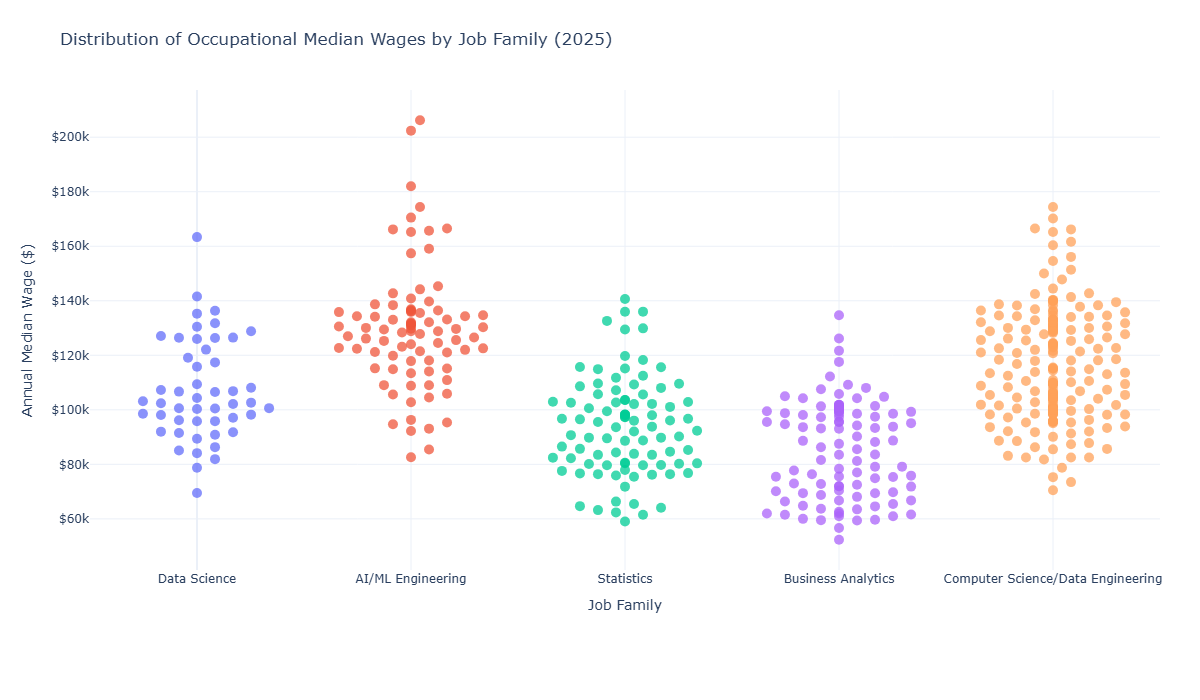

**Step 2: Organizing the dashboard**

After developing the charts individually, I moved the project to Streamlit and created a GitHub repository for the application, which supports CSV files and Python requirements.

The dashboard uses one scrolling page, with filters at the top followed by the map, state rankings, scatterplot, beeswarm, and time-series charts. This order moves from geographic patterns to employment and wage relationships, occupation-level distributions, and national trends.

Streamlit manages the layout and controls, while Plotly provides the interactive charts. The application loads three CSV files containing state-level job-family data, occupation-level wages, and national time-series data.

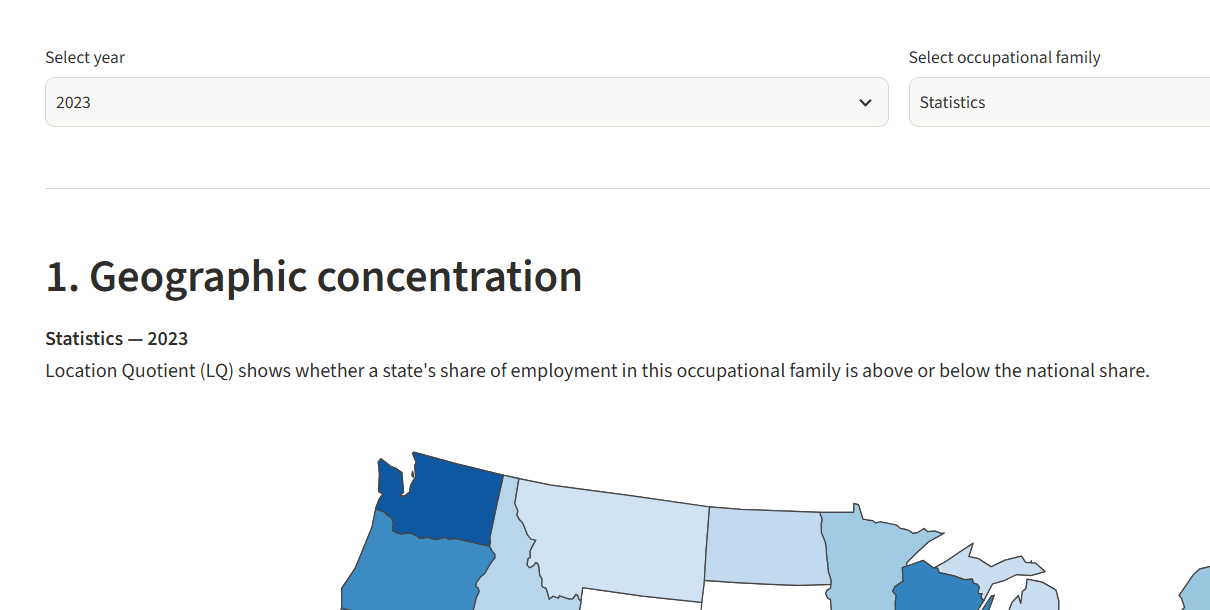

**Step 3: Adding linked interactivity**

I added two dropdown controls:

   **Select Year:** Filters the dashboard from 2021 through 2025.

   **Select Occupational Family:** Selects one of five job families.

The year selection updates the map, ranked bar chart, scatterplot, and beeswarm. The occupational-family selection updates the map, ranked bar chart, and scatterplot. The beeswarm continues to show all five families for the selected year, while the national time-series charts remain unchanged.

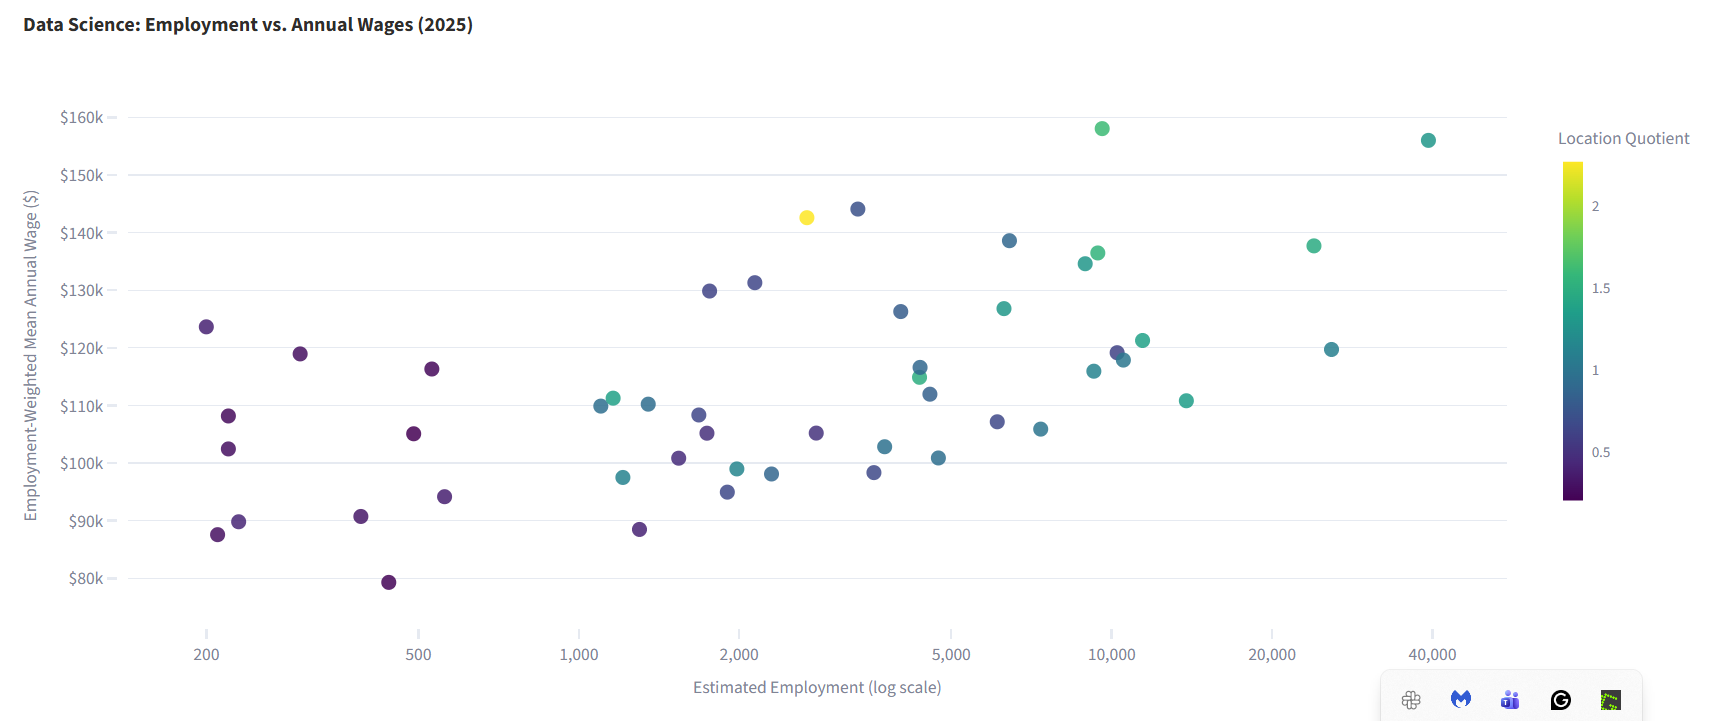

### Exploring the Data

I began by asking whether states with the highest concentration of data science-related employment also had the highest employment levels and wages.

The map and ranked bar chart revealed geographic differences in occupational concentration. The scatterplot showed that high employment, wages, and concentration do not necessarily occur in the same states. The beeswarm revealed wage variation across occupations and states, while the time series highlighted differences in national employment growth.

### Findings Through Interaction

The linked filters allowed me to compare years and job families across multiple visualizations.

In the 2025 Data Science results, Washington, Massachusetts, Utah, and New York had Location Quotients above the national average. Washington, D.C. also ranked highly but appears only in the bar chart because it is not a state polygon.

The most striking finding came from the employment time series: **Data Science employment grew approximately 147% between 2021 and 2025**, compared with approximately 24% for AI/ML Engineering and 17–20% for the other job families. Indexing each family to 100 in 2021 made these growth rates directly comparable and revealed a difference that was much less obvious in the raw employment figures.

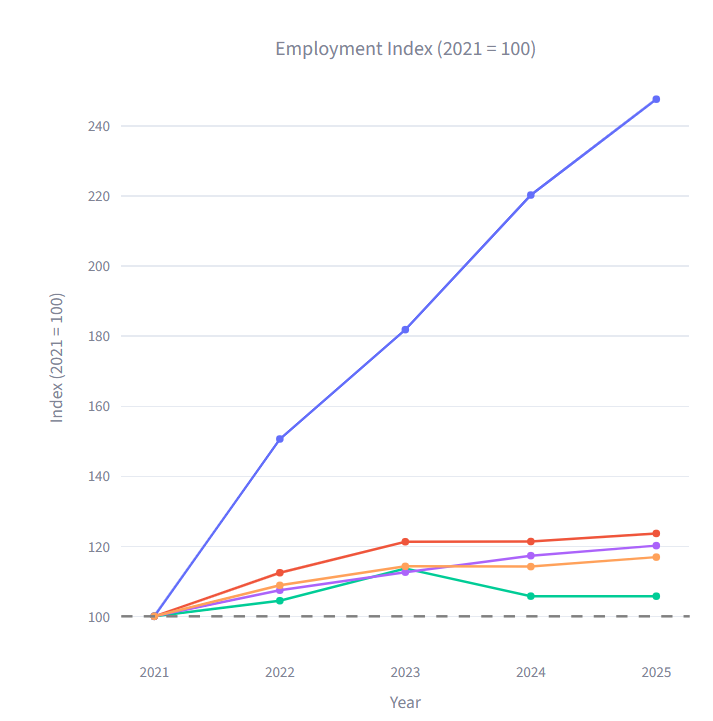

### Challenges and Adjustments

Transferring the Jupyter visualizations into Streamlit required checking that their appearance and behavior remained consistent. I compared the deployed charts with the originals and corrected differences in scatterplot formatting and beeswarm positioning.

I also discovered that the initial occupation-level CSV contained only 2025 data because of a year restriction in the export code. I removed the restriction, regenerated the file with all available years, and updated GitHub and the dashboard.

Finally, Vocareum was not suitable for public hosting. I moved the application to GitHub and Streamlit Community Cloud, making it accessible through a public URL without requiring installation.

These challenges reinforced the importance of validating the data, charts, and deployed application together.

# 6. AI Log and Troubleshooting

### Entry 1: Initial Project Scope

- **Tool:** ChatGPT
- **What I was trying to do:** Plan and develop the visualization project.
- **What happened:** Initial guidance focused too narrowly on building the dashboard.
- **What was wrong:** The assignment required three deliverables: an interactive dashboard, a narrative notebook, and a narrated video.
- **How I noticed:** Reviewing the assignment requirements revealed that the proposed workflow did not cover all three.
- **What I did instead:** I reorganized the workflow to include documentation, dashboard development, deployment, and video production.

### Entry 2: Incorrect Location Quotient Validation

- **Tool:** ChatGPT
- **What I was trying to do:** Validate calculated Location Quotients against the original BLS estimates.
- **What happened:** ChatGPT suggested a calculation that effectively divided the Location Quotient by itself.
- **What was wrong:** This was a tautological calculation, not an independent validation.
- **How I noticed:** Reviewing the formula showed it did not actually recompute the Location Quotient.
- **What I did instead:** I independently recalculated it using state and national employment shares. The maximum absolute difference from the original BLS values was 0.0.

### Entry 3: Python Syntax Error in Visualization Code

- **Tool:** ChatGPT
- **What I was trying to do:** Create and format interactive Plotly visualizations.
- **What happened:** A suggested code revision produced a `SyntaxError: positional argument follows keyword argument`.
- **What was wrong:** The function arguments were in an invalid order.
- **How I noticed:** Jupyter returned the syntax error when I ran the code.
- **What I did instead:** I corrected the argument order, and the visualization executed successfully.

# 7. Deployment Instructions

### Hosting with Streamlit Community Cloud

I used GitHub to store the dashboard application and supporting data, and Streamlit Community Cloud to host it publicly. The dashboard was developed in Vocareum Jupyter Notebook and deployed separately, allowing viewers to use it without installing Python or configuring an environment.

### Step 1: Prepare the Project Files

I exported three datasets from Jupyter Notebook:

- `dashboard_state.csv` – State-level employment, wage, and LQ data for five job families (2021–2025).
- `dashboard_occupation.csv` – State-level occupation wage observations for the beeswarm.
- `dashboard_time_series.csv` – National employment and wage indices (2021–2025).

I also created two application files:

- `app.py` – Streamlit layout, interactive controls, and Plotly charts.
- `requirements.txt` – Required Python libraries:

```text
streamlit==1.67.0
pandas
numpy
plotly
```

### Step 2: Create a GitHub Repository

I created a public repository named `data-science-labor-market` and uploaded all five files:

```text
data-science-labor-market/
├── app.py
├── requirements.txt
├── dashboard_state.csv
├── dashboard_occupation.csv
└── dashboard_time_series.csv
```

### Step 3: Deploy Through Streamlit Community Cloud

I opened [Streamlit Community Cloud](https://share.streamlit.io/), connected my GitHub account, and created an application using these settings:

1. Repository: `data-science-labor-market`
2. Branch: `main`
3. Application file: `app.py`

Streamlit installed the required libraries, loaded the datasets, and launched the dashboard.

### Step 4: Test the Published Dashboard

I checked that all five visualizations rendered, the year and occupational-family filters updated the appropriate charts, and the beeswarm displayed data for the selected year. I also checked chart labels and hover information.

**Live Dashboard:** [https://data-science-labor-market.streamlit.app/](https://data-science-labor-market.streamlit.app/)

### Step 5: Updating the Dashboard

To update the application, I make changes in Jupyter or the project files and commit the updated files to GitHub. For example, I corrected the occupation-level CSV export to include all five years and uploaded the replacement file.

Streamlit Community Cloud automatically detects GitHub changes and redeploys the application.

### Final Deployment

Vocareum supported data preparation and notebook development, GitHub stored the application and datasets, and Streamlit Community Cloud hosted the finished dashboard. The result is a publicly accessible application that requires no local installation or configuration.